In [ ]:
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import torch
import torchinfo
from torch import optim
from torch.utils.data import DataLoader

import torchtext.transforms as T
from torchlake.common.helpers.tokenizer import CharNgramTokenizer
from torchlake.common.helpers.transform import CustomVocabTransform
from torchlake.common.helpers.vocab import CharNgramVocab
from torchlake.common.schemas.nlp import NLPContext
from torchlake.common.utils.platform import get_file_size, get_num_workers
from torchlake.common.utils.text import get_unigram_counts, is_longer_text
from torchlake.common.utils.tree import build_huffman_tree
from torchlake.language_model.constants.enum import LossType
from torchlake.language_model.models.word2vec import HierarchicalSoftmaxLoss
from torchlake.text_classification.controller.fasttext import (
    FastTextTrainer,
    FastTextEvaluator,
)
from torchlake.text_classification.models.fasttext import FastText
from torchtext.data.utils import get_tokenizer

d:\research\pytorch-implementations\gits\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# setting


In [2]:
DATASET_NAME = "web-of-science"

In [3]:
artifact_path = Path("../../artifacts/fasttext")
artifact_path.mkdir(exist_ok=True)

artifact_dataset_path = artifact_path / DATASET_NAME
artifact_dataset_path.mkdir(exist_ok=True)

dataset_path = Path("../../data") / DATASET_NAME
cache_path = Path("../../data") / "hf"

In [4]:
CONTEXT = NLPContext(
    # word length, not ngram length
    max_seq_len=256,
)

In [5]:
BATCH_SIZE = 32
MINIMUM_LENGTH = 5

In [6]:
DEVICE = torch.device(CONTEXT.device)

In [7]:
# should be smaller than ngram size
BUCKET_SIZE = 1 * 10**5

In [8]:
NUM_WORKERS = get_num_workers()

# data

In [9]:
MINIMUM_LENGTH = 5

In [10]:
word_tokenizer = get_tokenizer("basic_english")
ngram_tokenizer = CharNgramTokenizer(
    word_tokenizer,
    # [3,4,5,6] is used in paper
    ngrams=[3, 4, 5, 6],
)

In [11]:
def dataset_factory(
    dataset: datasets.Dataset,
    minimum_length: int = 1,
    ngram_transform=None,
    word_transform=None,
    word_spans_transform=None,
):
    dataset = (
        dataset.map(lambda pair: {"text": pair["text"].strip()})
        .map(lambda pair: {"text": pair["text"].lower()})
        .filter(lambda pair: is_longer_text(pair["text"], minimum_length))
        .map(
            lambda pair: dict(
                zip(("subwords", "words", "word_spans"), ngram_tokenizer(pair["text"]))
            ),
            remove_columns=["text"],
        )
    )

    if ngram_transform is not None:
        dataset = dataset.map(
            lambda pair: {
                "subwords": ngram_transform(pair["subwords"]),
                "words": word_transform(pair["words"]),
                "word_spans": word_spans_transform(pair["word_spans"]),
            }
        )

    return dataset

In [12]:
dataset = datasets.load_dataset(
    "csv",
    data_files=dataset_path.joinpath("WOS46985/combined.txt").as_posix(),
    split="train",
    cache_dir=cache_path,
    delimiter="\t",
    column_names=["text", "label"],
)
dataset = dataset.class_encode_column("label")

dataset = dataset.train_test_split(test_size=0.1, stratify_by_column="label", seed=42)
train_dataset, val_dataset = dataset["train"], dataset["test"]

In [13]:
train_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 42286
})

In [14]:
train_dataset[0]

{'text': 'Background: Intermittent theta burst stimulation (iTBS) of the primary motor cortex improves transiently lower limbs spasticity in multiple sclerosis (MS). However, the cerebral mechanisms underlying this effect have never been investigated. Objective: To assess whether modulation of spasticity induced by iTBS is underlined by functional reorganization of the primary motor cortices. Methods: A total of 17 patients with MS suffering from lower limbs spasticity were randomized to receive real iTBS or sham iTBS during the first half of a 5-week indoor rehabilitation programme. Spasticity was assessed using the Modified Ashworth Scale and the Visual Analogue Scale at baseline, after the stimulation session and at the end of the rehabilitation programme. Resting-state functional magnetic resonance imaging (fMRI) was performed at the three time points, and brain functional networks topology was analysed using graph-theoretical approach. Results: At the end of stimulation, improveme

In [15]:
ngram_vocab = CharNgramVocab(context=CONTEXT, bucket_size=BUCKET_SIZE)

In [16]:
cloned_dataset_for_vocab_building = dataset_factory(train_dataset, MINIMUM_LENGTH)

In [17]:
ngram_vocab.build_word_vocab(
    map(lambda x: x["words"], cloned_dataset_for_vocab_building)
)

In [18]:
VOCAB_SIZE = len(ngram_vocab.word_vocab)
VOCAB_SIZE

47731

In [19]:
# build cache
# for row in cloned_dataset_for_vocab_building:
#     ngram_vocab.add_subtokens(row["subwords"])

In [20]:
# print("cache size:", len(ngram_vocab))

In [21]:
ngram_vocab.save_word_vocab(artifact_dataset_path / "words.json")
# ngram_vocab.save_subword_vocab(artifact_dataset_path / "grams.json")

In [22]:
ngram_vocab.load_word_vocab(artifact_dataset_path / "words.json")
# ngram_vocab.load_subword_vocab(artifact_dataset_path / "grams.json")

In [23]:
get_file_size(artifact_dataset_path / "words.json")

'0.85MiB'

In [24]:
# get_file_size(artifact_dataset_path / "grams.json")

In [25]:
ngram_transform = T.Sequential(
    CustomVocabTransform(ngram_vocab),
    T.ToTensor(),
)

In [26]:
word_transform = T.Sequential(
    # T.VocabTransform(ngram_vocab.word_vocab),
    CustomVocabTransform(ngram_vocab),
    T.Truncate(CONTEXT.max_seq_len),
    T.ToTensor(),
    T.PadTransform(CONTEXT.max_seq_len, CONTEXT.padding_idx),
)

In [27]:
word_spans_transform = T.Sequential(
    T.Truncate(CONTEXT.max_seq_len),
    T.ToTensor(),
)

In [28]:
ngram_vocab.word_vocab.set_default_index(CONTEXT.unk_idx)

In [29]:
train_dataset = dataset_factory(
    train_dataset,
    MINIMUM_LENGTH,
    ngram_transform,
    word_transform,
    word_spans_transform,
)

In [30]:
for i in range(5):
    row = train_dataset.with_format("torch")[i]
    grams, words, word_lengths = row["subwords"], row["words"], row["word_spans"]
    label = row["label"]
    print(grams.shape)
    print(words.shape)
    print(word_lengths.shape)
    print(label)

torch.Size([2799])
torch.Size([256])
torch.Size([248])
tensor(11)
torch.Size([3353])
torch.Size([256])
torch.Size([256])
tensor(107)
torch.Size([2828])
torch.Size([256])
torch.Size([241])
tensor(70)
torch.Size([3673])
torch.Size([256])
torch.Size([256])
tensor(99)
torch.Size([3246])
torch.Size([256])
torch.Size([253])
tensor(25)


In [31]:
def collate_fn(
    batch: list[dict],
) -> tuple[list[torch.Tensor], list[torch.Tensor], list[torch.Tensor], torch.Tensor]:
    ngrams, words, word_spans = [], [], []
    labels = []

    for row in batch:
        ngram, word, word_span = row["subwords"], row["words"], row["word_spans"]
        label = row["label"]
        # truncate ngram with word length
        ngrams.append(ngram[: sum(word_span)])
        words.append(word)
        word_spans.append(word_span)
        labels.append(label)

    # B x (sum_word_span)   # B, max_seq_len  # B x (num_word)    # B
    return (ngrams, torch.stack(words), word_spans), torch.tensor(
        labels, dtype=torch.long
    )

In [32]:
train_dataloader = DataLoader(
    train_dataset.with_format("torch"),
    batch_size=BATCH_SIZE,
    pin_memory=True,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

In [33]:
count = 0
for (grams, words, word_spans), label in train_dataloader:
    print(len(grams), *[gram.shape for gram in grams[:4]])
    print(words.shape)
    print(len(word_spans), *[word_span.shape for word_span in word_spans[:4]])
    print(label.shape)
    if count > 10:
        break
    count += 1

32 torch.Size([2160]) torch.Size([2373]) torch.Size([3194]) torch.Size([1095])
torch.Size([32, 256])
32 torch.Size([163]) torch.Size([179]) torch.Size([256]) torch.Size([105])
torch.Size([32])
32 torch.Size([1593]) torch.Size([1981]) torch.Size([2448]) torch.Size([3209])
torch.Size([32, 256])
32 torch.Size([153]) torch.Size([189]) torch.Size([209]) torch.Size([256])
torch.Size([32])
32 torch.Size([1903]) torch.Size([2989]) torch.Size([2884]) torch.Size([2788])
torch.Size([32, 256])
32 torch.Size([158]) torch.Size([236]) torch.Size([256]) torch.Size([256])
torch.Size([32])
32 torch.Size([1783]) torch.Size([1607]) torch.Size([3113]) torch.Size([2142])
torch.Size([32, 256])
32 torch.Size([182]) torch.Size([136]) torch.Size([256]) torch.Size([185])
torch.Size([32])
32 torch.Size([2255]) torch.Size([3037]) torch.Size([2923]) torch.Size([1835])
torch.Size([32, 256])
32 torch.Size([179]) torch.Size([256]) torch.Size([228]) torch.Size([137])
torch.Size([32])
32 torch.Size([1473]) torch.Size([2

In [34]:
NUM_CLASS = max(train_dataset["label"]) + 1
NUM_CLASS

134

# training


## baseline

In [90]:
EMBED_DIM = 300

In [93]:
baseline = FastText(
    BUCKET_SIZE,
    EMBED_DIM,
    NUM_CLASS,
    loss_type=LossType.CROSS_ENTROPY,
    context=CONTEXT,
).to(DEVICE)

In [94]:
torchinfo.summary(baseline)

Layer (type:depth-idx)                   Param #
FastText                                 --
├─SubwordEmbedding: 1-1                  --
│    └─Embedding: 2-1                    30,000,000
│    └─Embedding: 2-2                    1,200
├─Linear: 1-2                            40,334
Total params: 30,041,534
Trainable params: 30,041,534
Non-trainable params: 0

In [95]:
EPOCHS = 10
ACC_ITERS = max(32 / BATCH_SIZE, 1)
LR = 1e-3

In [96]:
trainer = FastTextTrainer(EPOCHS, DEVICE, ACC_ITERS, feature_last=True)

In [97]:
trainer.recorder.increment_dataset_size(len(train_dataset))

In [98]:
criterion = trainer.get_criterion(NUM_CLASS)
optimizer = optim.Adam(baseline.parameters(), lr=LR)

In [99]:
training_loss = trainer.run(train_dataloader, baseline, optimizer, criterion)

Enable AMP: False
Training...


100%|██████████| 1321/1321 [01:37<00:00, 13.62it/s]


------------------------------------
Epoch 1
------------------------------------
total: 1.3116e-01 (0.00%)


100%|██████████| 1321/1321 [01:40<00:00, 13.14it/s]


------------------------------------
Epoch 2
------------------------------------
total: 8.9551e-02 (-32.00%)


100%|██████████| 1321/1321 [01:37<00:00, 13.49it/s]


... (11 outputs left out)

100%|██████████| 1321/1321 [01:36<00:00, 13.63it/s]


------------------------------------
Epoch 9
------------------------------------
total: 1.6216e-02 (-20.00%)


100%|██████████| 1321/1321 [01:35<00:00, 13.89it/s]

------------------------------------
Epoch 10
------------------------------------
total: 1.2890e-02 (-21.00%)


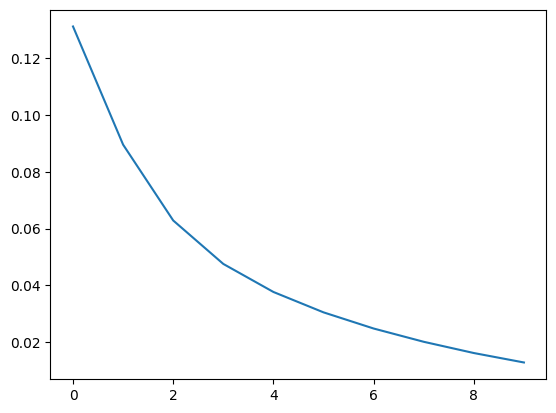

In [100]:
plt.plot(training_loss)

### file

In [101]:
from torchlake.common.controller.weight_manager import WeightManager

In [102]:
wm = WeightManager(
    artifact_path.joinpath(
        "fasttext.{embed_dim}.{dataset_name}.loss.{loss_type}.pth"
    ).as_posix()
)
model_path = wm.get_filename(
    embed_dim=EMBED_DIM, dataset_name=DATASET_NAME, loss_type=baseline.loss_type.name
)
model_path

WindowsPath('../../artifacts/fasttext/fasttext.300.web-of-science.loss.CROSS_ENTROPY.pth')

In [103]:
wm.save_weight(baseline.state_dict(), model_path)

Save weight to ..\..\artifacts\fasttext\fasttext.300.web-of-science.loss.CROSS_ENTROPY.pth, model size is 114.6MiB


In [ ]:
wm.load_weight(model_path, baseline)

## hierarchical softmax

In [ ]:
word_counts = get_unigram_counts(
    map(lambda it: (it["label"],), train_dataset), NUM_CLASS
)

<BarContainer object of 134 artists>

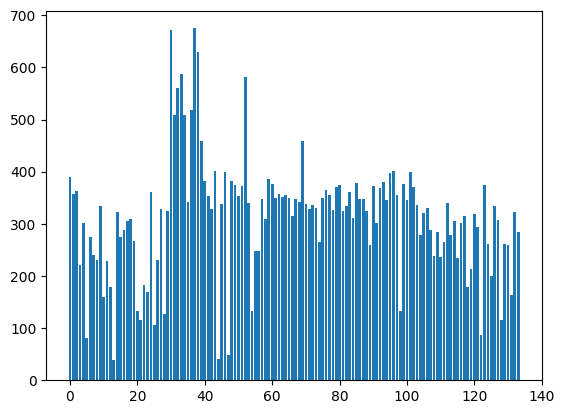

In [ ]:
plt.bar(torch.arange(len(word_counts)), word_counts)

In [37]:
EMBED_DIM = 300

In [38]:
root = build_huffman_tree(word_counts)

In [39]:
model = FastText(
    BUCKET_SIZE,
    EMBED_DIM,
    NUM_CLASS,
    loss_type=LossType.HIERARCHICAL_SOFTMAX,
    context=CONTEXT,
    root=root,
).to(DEVICE)

In [40]:
torchinfo.summary(model)

Layer (type:depth-idx)                   Param #
FastText                                 --
├─SubwordEmbedding: 1-1                  --
│    └─Embedding: 2-1                    30,000,000
│    └─Embedding: 2-2                    1,200
├─HierarchicalSoftmax: 1-2               --
│    └─Embedding: 2-3                    39,900
Total params: 30,041,100
Trainable params: 30,041,100
Non-trainable params: 0

In [41]:
EPOCHS = 10
ACC_ITERS = max(32 / BATCH_SIZE, 1)
LR = 1e-3

In [42]:
trainer = FastTextTrainer(EPOCHS, DEVICE, ACC_ITERS, feature_last=True)

In [43]:
trainer.recorder.increment_dataset_size(len(train_dataset))

In [44]:
criterion = HierarchicalSoftmaxLoss(root, NUM_CLASS, context=CONTEXT)
optimizer = optim.Adam(model.parameters(), lr=LR)

In [45]:
training_loss = trainer.run(train_dataloader, model, optimizer, criterion)

Enable AMP: False
Training...


100%|██████████| 1321/1321 [01:46<00:00, 12.40it/s]


------------------------------------
Epoch 1
------------------------------------
total: 2.2530e-02 (0.00%)


100%|██████████| 1321/1321 [01:41<00:00, 12.98it/s]


------------------------------------
Epoch 2
------------------------------------
total: 1.1563e-02 (-49.00%)


100%|██████████| 1321/1321 [01:42<00:00, 12.92it/s]


... (11 outputs left out)

100%|██████████| 1321/1321 [01:40<00:00, 13.19it/s]


------------------------------------
Epoch 9
------------------------------------
total: 2.0321e-03 (-18.00%)


100%|██████████| 1321/1321 [01:39<00:00, 13.30it/s]

------------------------------------
Epoch 10
------------------------------------
total: 1.6667e-03 (-18.00%)


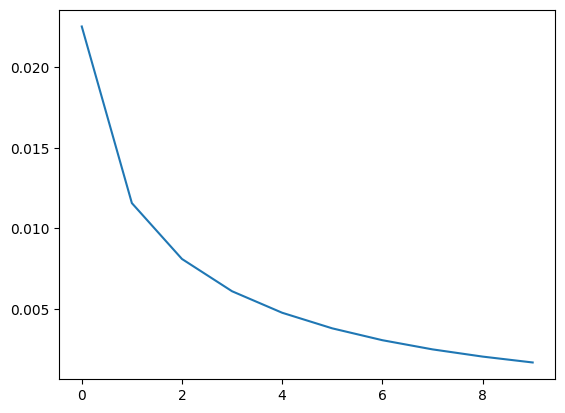

In [46]:
plt.plot(training_loss)

### file

In [ ]:
from torchlake.common.controller.weight_manager import WeightManager

In [ ]:
wm = WeightManager(
    artifact_path.joinpath(
        "fasttext.{embed_dim}.{dataset_name}.loss.{loss_type}.pth"
    ).as_posix()
)
model_path = wm.get_filename(
    embed_dim=EMBED_DIM, dataset_name=DATASET_NAME, loss_type=model.loss_type.name
)
model_path

WindowsPath('../../artifacts/fasttext/fasttext.300.web-of-science.loss.HIERARCHICAL_SOFTMAX.pth')

In [ ]:
wm.save_weight(model.state_dict(), model_path)

Save weight to ..\..\artifacts\fasttext\fasttext.300.web-of-science.loss.HIERARCHICAL_SOFTMAX.pth, model size is 114.61MiB


In [ ]:
wm.load_weight(model_path, model)

# Evaluation

In [47]:
ngram_vocab.word_vocab.set_default_index(CONTEXT.unk_idx)

In [48]:
val_dataset = dataset_factory(
    val_dataset,
    MINIMUM_LENGTH,
    ngram_transform,
    word_transform,
    word_spans_transform,
)

Map:   0%|          | 0/4699 [00:00<?, ? examples/s]

Map: 100%|██████████| 4699/4699 [00:31<00:00, 150.52 examples/s]


In [64]:
val_dataloader = DataLoader(
    val_dataset.with_format("torch"),
    batch_size=BATCH_SIZE,
    pin_memory=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

## baseline

In [111]:
evaluator = FastTextEvaluator(NUM_CLASS, DEVICE, feature_dim=-1)

In [112]:
confusion_matrix = evaluator.run(val_dataloader, baseline)

100%|██████████| 147/147 [00:12<00:00, 11.98it/s]


In [113]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(NUM_CLASS), per_class_acc)

0         : 0.6744186046511628
1         : 0.575
2         : 0.475
3         : 0.96
4         : 0.5588235294117647
5         : 0.6666666666666666
6         : 0.8666666666666667
7         : 0.7037037037037037
8         : 0.52
9         : 0.7567567567567568
10        : 0.05555555555555555
11        : 0.68
12        : 0.7
13        : 0.0
14        : 0.4444444444444444
15        : 0.7333333333333333
16        : 0.78125
17        : 0.8235294117647058
18        : 0.5294117647058824
19        : 0.6666666666666666
20        : 0.5333333333333333
21        : 0.38461538461538464
22        : 0.65
23        : 0.47368421052631576
24        : 0.9
25        : 0.6666666666666666
26        : 0.8076923076923077
27        : 0.8888888888888888
28        : 0.35714285714285715
29        : 0.4722222222222222
30        : 0.56
31        : 0.6491228070175439
32        : 0.8387096774193549
33        : 0.5076923076923077
34        : 0.5263157894736842
35        : 0.42105263157894735
36        : 0.7586206896551724


In [114]:
per_class_acc.mean()

np.float64(0.6510063014416573)

<BarContainer object of 134 artists>

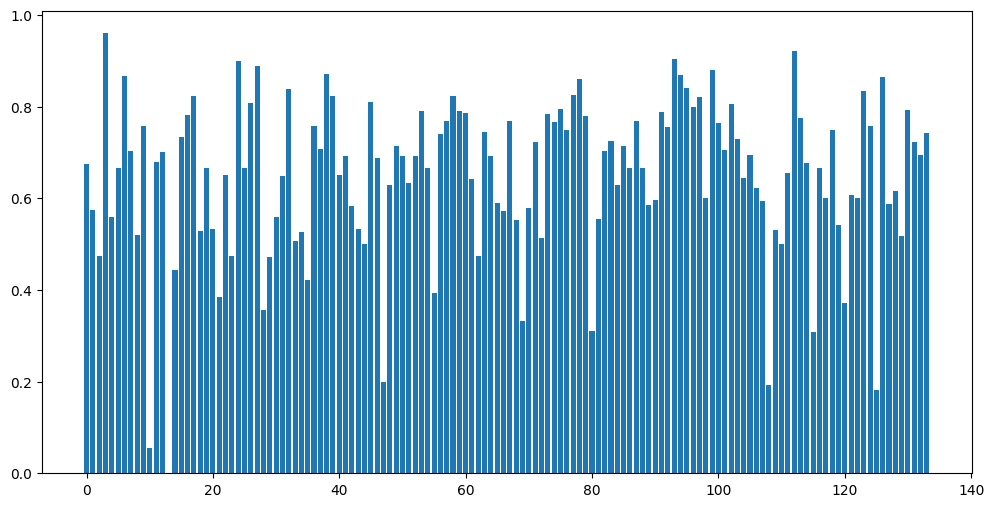

In [115]:
plt.figure(figsize=(12, 6))
plt.bar(range(NUM_CLASS), per_class_acc)

## hierarchical softmax

In [80]:
evaluator = FastTextEvaluator(NUM_CLASS, DEVICE, feature_dim=-1, reduction=None)

In [82]:
confusion_matrix = evaluator.run(val_dataloader, model)

100%|██████████| 147/147 [00:15<00:00,  9.56it/s]


In [83]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(NUM_CLASS), per_class_acc)

0         : 0.4883720930232558
1         : 0.275
2         : 0.55
3         : 0.88
4         : 0.5
5         : 0.6666666666666666
6         : 0.7666666666666667
7         : 0.4444444444444444
8         : 0.6
9         : 0.43243243243243246
10        : 0.05555555555555555
11        : 0.52
12        : 0.6
13        : 0.0
14        : 0.19444444444444445
15        : 0.5666666666666667
16        : 0.5625
17        : 0.8235294117647058
18        : 0.5
19        : 0.6
20        : 0.26666666666666666
21        : 0.38461538461538464
22        : 0.5
23        : 0.2631578947368421
24        : 0.8
25        : 0.3333333333333333
26        : 0.6153846153846154
27        : 0.8333333333333334
28        : 0.35714285714285715
29        : 0.4166666666666667
30        : 0.4
31        : 0.45614035087719296
32        : 0.6935483870967742
33        : 0.36923076923076925
34        : 0.3684210526315789
35        : 0.23684210526315788
36        : 0.7241379310344828
37        : 0.64
38        : 0.714285714285714

In [84]:
per_class_acc.mean()

np.float64(0.5271849961419082)

<BarContainer object of 134 artists>

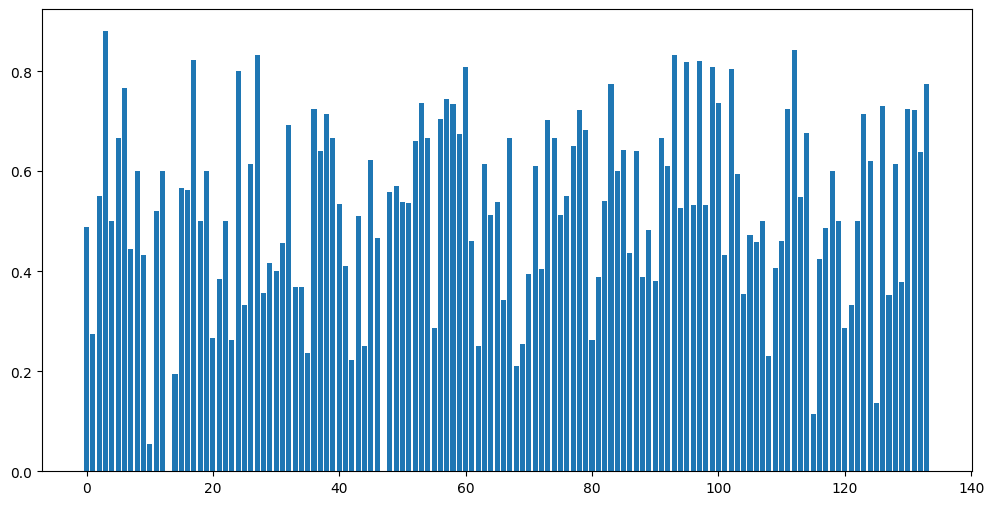

In [89]:
plt.figure(figsize=(12, 6))
plt.bar(range(NUM_CLASS), per_class_acc)